In [55]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, f_oneway, ttest_ind

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

In [56]:
df = pd.read_csv("/content/customer_churn_raw_1100_rows.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df

Dataset loaded successfully.
Shape: (1100, 30)


,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,Subscription_Plan,Monthly_Charges,Total_Charges,Payment_Method,Auto_Payment,Support_Calls,Complaints,Internet_Usage_GB,Avg_Session_Minutes,Login_Frequency,Discount,Satisfaction_Score,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source
0,cus_0249,ananya rao,M,38 years,warangal,telangana,Jul 11 2026,08/27/2026,1 months,M2M,Basic,Customer pays 0.6K monthly,Customer paid 0.5K,UPI,N,-,3 complaints,13.9,44.3,Monthly,Customer receives 25% discount,2 out of 5,Poor,Mobile,friend referral,Active,NaN,Not churned,NaN,CRM
1,cus_0106,Riya Kapoor,Male,49,Tirupati,Andhra Pradesh,Aug 26 2024,08/22/2026,24,Two-Year,basic,560,Customer paid 10.6K,debit_card,No,1 calls,1,23.0 GB,0.6 hours,Daily,No Discount,Average,4 stars,android phone,Friend,0,NaN,Not churned,customer happy with service,mobile app
2,cus_0197,SURESH BABU,F,26,NaN,Delhi,2026-07-21,2026-08-27,1,Monthly,Basic,The monthly charges is ₹452,415,NaN,N,6,0 complaints,21.1 GB,87 mins,Daily,0.10,5,Excellent,Android Phone,Google,0,NaN,NaN,moved to competitor,Mobile App
3,CUS-0891,Sneha Patel,Female,55,delhi,Not Available,16-Apr-26,30-Aug-26,1 years,Monthly,pro,"₹ 1,622.00 per month",Customer paid 5.1K,Debit Card,yes,2 calls,1,18.4 GB,0.2 hours,2-3 times/week,5%,Very Satisfied,Not Available,iPhone,Google,N,NaN,NaN,NaN,API
4,CUS-0333,amit shah,M,39,Not Available,Telangana,Jul 14 2026,08/27/2026,1 years,Monthly,PREMIUM,Customer pays 1.4K monthly,"₹1,202",NaN,Yes,Customer contacted support 0 times,Reported 1 issues,Not Available,75 mins,weekly,15%,3 out of 5,2,Android,Google,No,NaN,NaN,customer happy with service,Import
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,Customer_1069,Lakshmi Devi,M,18,New Delhi,delhi,07-Jun-25,NaN,15M,Monthly,PREMIUM,Monthly charge: Rs. 900,"Total amount paid = ₹13,570",bank transfer,1,Customer contacted support 3 times,1,30.2,27 mins,Daily,10%,Good,Good,Android,google search,No,NaN,NaN,called support 3 times!!!,Website
1096,CUS-0024,Divya Iyer,Female,18,Chennai,Tamil Nadu,09/16/2024,Aug 29 2026,23M,Monthly,BASIC,876,"Total charges: ₹19,945",upi,Yes,0 calls,1 complaints,12.4,Average session: 81 minutes,Daily,Customer receives 25% discount,4 out of 5,NaN,android phone,Social Media,0,NaN,NaN,no major issues,Website
1097,CUS-0392,rohit mehta,Male,49,MADRAS,tamil nadu,27/12/2024,01/08/2026,20 months,Monthly,Premium,NaN,"₹17,992",debit_card,Yes,Customer contacted support 2 times,0 complaints,7.2,0.5 hours,Daily,25%,2 out of 5,3 stars,Android Phone,Social Media,1,2026-08-01,Bad service,payment issue reported,CRM
1098,Customer_0825,swathi reddy,NaN,36,Unknown,Karnataka,09/21/2024,29/08/2026,1.9 years,M2M,Premium,Customer pays 1.2K monthly,"Total amount paid = ₹20,909",Credit Card,Yes,4 calls,2,25.3,31.0,Weekly,Customer receives 5% discount,3,3 stars,Mobile,Friend,Active,NaN,NaN,asked for discount,Import


In [57]:
display(df.head(10))

,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,Subscription_Plan,Monthly_Charges,Total_Charges,Payment_Method,Auto_Payment,Support_Calls,Complaints,Internet_Usage_GB,Avg_Session_Minutes,Login_Frequency,Discount,Satisfaction_Score,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source
0,cus_0249,ananya rao,M,38 years,warangal,telangana,Jul 11 2026,08/27/2026,1 months,M2M,Basic,Customer pays 0.6K monthly,Customer paid 0.5K,UPI,N,-,3 complaints,13.9,44.3,Monthly,Customer receives 25% discount,2 out of 5,Poor,Mobile,friend referral,Active,NaN,Not churned,NaN,CRM
1,cus_0106,Riya Kapoor,Male,49,Tirupati,Andhra Pradesh,Aug 26 2024,08/22/2026,24,Two-Year,basic,560,Customer paid 10.6K,debit_card,No,1 calls,1,23.0 GB,0.6 hours,Daily,No Discount,Average,4 stars,android phone,Friend,0,NaN,Not churned,customer happy with service,mobile app
2,cus_0197,SURESH BABU,F,26,NaN,Delhi,2026-07-21,2026-08-27,1,Monthly,Basic,The monthly charges is ₹452,415,NaN,N,6,0 complaints,21.1 GB,87 mins,Daily,0.10,5,Excellent,Android Phone,Google,0,NaN,NaN,moved to competitor,Mobile App
3,CUS-0891,Sneha Patel,Female,55,delhi,Not Available,16-Apr-26,30-Aug-26,1 years,Monthly,pro,"₹ 1,622.00 per month",Customer paid 5.1K,Debit Card,yes,2 calls,1,18.4 GB,0.2 hours,2-3 times/week,5%,Very Satisfied,Not Available,iPhone,Google,N,NaN,NaN,NaN,API
4,CUS-0333,amit shah,M,39,Not Available,Telangana,Jul 14 2026,08/27/2026,1 years,Monthly,PREMIUM,Customer pays 1.4K monthly,"₹1,202",NaN,Yes,Customer contacted support 0 times,Reported 1 issues,Not Available,75 mins,weekly,15%,3 out of 5,2,Android,Google,No,NaN,NaN,customer happy with service,Import
5,CUS-0116,Meera Nair,Male,18,Baroda,GJ,NaN,Aug 17 2026,10,M2M,premium,"The monthly charges is ₹1,269",10260,Credit Card,Unknown,Customer contacted support 2 times,0 complaints,Usage: 10.7 GB,59.0,daily,0.00,Good,4 stars,Android,Friend,No,NaN,Not churned,customer wants faster service,Mobile App
6,Customer_0297,ANANYA RAO,Male,23 years,coimbatore,tamil nadu,Jul 13 2026,NaN,1 years,Monthly,Pro plan,"Rs. 1,953","Total charges: ₹1,508",Bank Transfer,Y,1,2 complaints,9.5,0.9 hours,Monthly,Customer receives 25% discount,3 out of 5,2 stars,Mobile,NaN,Active,NaN,Not churned,moved to competitor,crm_import
7,Customer_0605,Harsha Vardhan,Female,24,Tirupati,Andhra Pradesh,2023-06-09,24-Aug-26,39 months,M2M,Basic plan,₹ 648.00 per month,"₹25,035",NaN,1,Customer contacted support 5 times,No complaints,Usage: 10.2 GB,62 mins,weekly,Discount = 25%,4 out of 5,3,Laptop,NaN,No,NaN,Not churned,called support 3 times!!!,mobile app
8,CUS-0775,Rahul Sharma,Male,51 years,vijayawada,AP,2025-08-06,2026-08-25,1.1 years,Monthly,PREMIUM,"₹1,504","₹18,184",CC,Yes,4 calls,1,28.7 GB,Average session: 28 minutes,weekly,0.10,Good,3,Android,Advertisement,0,NaN,NaN,asked for discount,Mobile App
9,Customer_0175,pooja nair,female,44,Baroda,GJ,22-Jun-26,NaN,2 months,Annual,PREMIUM,₹833,"Total charges: ₹1,708",Credit Card,yes,1,2 complaints,Usage: 74.4 GB,Average session: 65 minutes,Daily,Discount = 15%,Very Satisfied,5 stars,IOS,social media,No,NaN,NaN,no major issues,crm_import


In [58]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Rows: 1100
Columns: 30

Column names:
['Customer_ID', 'Customer_Name', 'Gender', 'Age', 'City', 'State', 'Signup_Date', 'Last_Login', 'Tenure', 'Contract_Type', 'Subscription_Plan', 'Monthly_Charges', 'Total_Charges', 'Payment_Method', 'Auto_Payment', 'Support_Calls', 'Complaints', 'Internet_Usage_GB', 'Avg_Session_Minutes', 'Login_Frequency', 'Discount', 'Satisfaction_Score', 'Customer_Service_Rating', 'Device_Type', 'Referral_Source', 'Churn', 'Churn_Date', 'Churn_Reason', 'Customer_Notes', 'Data_Source']


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Customer_ID              1100 non-null   object
 1   Customer_Name            1100 non-null   object
 2   Gender                   1060 non-null   object
 3   Age                      1053 non-null   object
 4   City                     978 non-null    object
 5   State                    1012 non-null   object
 6   Signup_Date              1079 non-null   object
 7   Last_Login               820 non-null    object
 8   Tenure                   1068 non-null   object
 9   Contract_Type            1085 non-null   object
 10  Subscription_Plan        1074 non-null   object
 11  Monthly_Charges          1064 non-null   object
 12  Total_Charges            1054 non-null   object
 13  Payment_Method           1075 non-null   object
 14  Auto_Payment             1065 non-null  

In [60]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
Churn_Date,873,79.36
Churn_Reason,654,59.45
Last_Login,280,25.45
Customer_Notes,199,18.09
Referral_Source,164,14.91
City,122,11.09
State,88,8.00
Login_Frequency,72,6.55
Avg_Session_Minutes,62,5.64
Device_Type,54,4.91


In [61]:
placeholder_values = ["N/A", "NA", "NULL", "-", "Unknown", "Not Available", "", "None"]

placeholder_summary = {}

for col in df.columns:
    count = df[col].astype(str).isin(placeholder_values).sum()
    if count > 0:
        placeholder_summary[col] = count

placeholder_summary = pd.Series(placeholder_summary).sort_values(ascending=False)
display(placeholder_summary.to_frame("Placeholder_Count"))

,Placeholder_Count
City,65
State,51
Internet_Usage_GB,42
Complaints,37
Total_Charges,36
Age,34
Auto_Payment,34
Avg_Session_Minutes,33
Monthly_Charges,31
Referral_Source,31


In [62]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Customer_ID values:", df["Customer_ID"].duplicated().sum())

duplicate_ids = df[df["Customer_ID"].duplicated(keep=False)].sort_values("Customer_ID")
display(duplicate_ids.head(20))

Exact duplicate rows: 15
Duplicate Customer_ID values: 31


,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,Subscription_Plan,Monthly_Charges,Total_Charges,Payment_Method,Auto_Payment,Support_Calls,Complaints,Internet_Usage_GB,Avg_Session_Minutes,Login_Frequency,Discount,Satisfaction_Score,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source
109,CUS-0049,Pooja Nair,male,54,Karimnagar,TELANGANA,Sep 23 2024,24/08/2026,23M,Monthly,premium,"₹ 1,168.00 per month","Total amount paid = ₹21,802",Debit Card,1,Customer contacted support 4 times,0 complaints,11.5,Average session: 20 minutes,Daily,0,4 out of 5,5 stars,Android,friend referral,Active,NaN,NaN,called support 3 times!!!,CRM
767,CUS-0049,Pooja Nair,male,54,Karimnagar,TELANGANA,Sep 23 2024,24/08/2026,23M,Monthly,premium,"₹ 1,168.00 per month","Total amount paid = ₹21,802",Debit Card,1,Customer contacted support 4 times,0 complaints,11.5,Average session: 20 minutes,Daily,0,4 out of 5,5 stars,Android,friend referral,Active,NaN,NaN,called support 3 times!!!,CRM
999,CUS-0097,ANANYA RAO,M,49,pune,NaN,2026-07-03,NaN,1 years,month-to-month,Premium plan,"₹ 1,486.00 per month","₹3,099",Credit Card,Y,1,0 complaints,Usage: 19.7 GB,52 mins,Weekly,NaN,5 out of 5,4,Android,Advertisement,1,09/04/2026,Moved to competitor,customer wants faster service,Import
223,CUS-0097,kiran das,Female,33 years,Kozhikode,kerala,2026-07-25,09/01/2026,1 months,Annual,Premium,"₹ 1,346.00 per month","₹1,373",Credit Card,Yes,Customer contacted support 4 times,Reported 1 issues,Not Available,32.0,Daily,NaN,Average,2,NaN,social media,No,NaN,Not churned,renewal discussed,crm_import
761,CUS-0117,Harsha Vardhan,Female,56,Madurai,tamil nadu,07/27/2026,22-Aug-26,1M,M2M,Unknown,-,"Total charges: ₹1,354",debit_card,N,4 calls,No complaints,31.6,50 mins,2-3 times/week,0%,4 out of 5,Excellent,IOS,NaN,Active,NaN,NaN,no major issues,website
268,CUS-0117,Harsha Vardhan,Female,56,Madurai,tamil nadu,07/27/2026,22-Aug-26,1M,M2M,Unknown,-,"Total charges: ₹1,354",debit_card,N,4 calls,No complaints,31.6,50 mins,2-3 times/week,0%,4 out of 5,Excellent,IOS,NaN,Active,NaN,NaN,no major issues,website
224,CUS-0382,harsha vardhan,male,18 years,mangalore,Karnataka,Jan 03 2026,NaN,8M,Yearly,Premium plan,803,Customer paid 6.2K,CC,Y,Customer contacted support 1 times,3 complaints,4.7,41.6,Daily,10%,3,3,android phone,NaN,0,NaN,NaN,asked for discount,mobile app
420,CUS-0382,Amit Shah,female,29 years,New Delhi,Delhi,Jul 16 2026,07/26/2026,1 months,Monthly,Basic plan,The monthly charges is ₹633,Total amount paid = ₹551,CC,1,Customer contacted support 4 times,0,NaN,58 mins,Rarely,0.10,Unknown,Average,IOS,Website,N,NaN,NaN,moved to competitor,CRM
732,CUS-0423,Ananya Rao,NaN,47 years,NaN,Maharashtra,30-Aug-23,NaN,3.0 years,month-to-month,Premium plan,Customer pays 1.6K monthly,"Total charges: ₹46,408",bank transfer,0,4 calls,Reported 1 issues,17.2,Average session: 58 minutes,weekly,0.15,4,Average,Android Phone,google search,N,NaN,NaN,no major issues,Website
509,CUS-0423,Ananya Rao,NaN,47 years,NaN,Maharashtra,30-Aug-23,NaN,3.0 years,month-to-month,Premium plan,Customer pays 1.6K monthly,"Total charges: ₹46,408",bank transfer,0,4 calls,Reported 1 issues,17.2,Average session: 58 minutes,weekly,0.15,4,Average,Android Phone,google search,N,NaN,NaN,no major issues,Website


In [63]:
categorical_columns_raw = [
    "Gender", "City", "State", "Contract_Type",
    "Subscription_Plan", "Payment_Method", "Auto_Payment",
    "Login_Frequency", "Device_Type", "Referral_Source",
    "Churn", "Data_Source"
]

for col in categorical_columns_raw:
    print(f"\n{'='*70}\n{col}")
    print(df[col].value_counts(dropna=False).head(30))


Gender
Gender
male             184
Male             181
F                175
female           171
Female           167
M                162
NaN               40
Not Available      7
Unknown            7
-                  6
Name: count, dtype: int64

City
City
NaN                   122
Unknown                33
Salem                  23
delhi                  22
new delhi              21
guntur                 19
DELHI                  19
Karimnagar             19
Not Available          17
thrissur               17
New Delhi              17
Surat                  17
Trivandrum             17
madurai                16
Vijayawada             16
Nagpur                 15
Delhi                  15
Madurai                15
-                      15
tirupati               15
CBE                    14
Cochin                 13
coimbatore             13
mangalore              13
Tirupati               13
karimnagar             13
NEW DELHI              13
rajkot                 13
Thiruvanan

In [64]:
raw_df = df.copy()
clean_df = df.copy()

print("Raw shape:", raw_df.shape)
print("Working shape:", clean_df.shape)

Raw shape: (1100, 30)
Working shape: (1100, 30)


In [65]:
clean_df["Customer_ID"] = (
    clean_df["Customer_ID"]
    .astype("string")
    .str.upper()
    .str.replace(r"^CUSTOMER[_-]", "CUS-", regex=True)
    .str.replace("_", "-", regex=False)
    .str.strip()
)

# Keep the first occurrence of a duplicated ID.
clean_df = clean_df.drop_duplicates(subset="Customer_ID", keep="first").copy()

print("Unique Customer_ID count:", clean_df["Customer_ID"].nunique())
print("Rows after duplicate-ID removal:", len(clean_df))

Unique Customer_ID count: 1069
Rows after duplicate-ID removal: 1069


In [66]:
clean_df["Customer_Name"] = (
    clean_df["Customer_Name"]
    .astype("string")
    .str.strip()
    .str.title()
)

clean_df["Customer_Name"] = clean_df["Customer_Name"].replace(
    ["Nan", "None", "N/A", "Na"], pd.NA
)

print("Missing names:", clean_df["Customer_Name"].isna().sum())
display(clean_df[["Customer_ID", "Customer_Name"]].head(10))

Missing names: 0


,Customer_ID,Customer_Name
0,CUS-0249,Ananya Rao
1,CUS-0106,Riya Kapoor
2,CUS-0197,Suresh Babu
3,CUS-0891,Sneha Patel
4,CUS-0333,Amit Shah
5,CUS-0116,Meera Nair
6,CUS-0297,Ananya Rao
7,CUS-0605,Harsha Vardhan
8,CUS-0775,Rahul Sharma
9,CUS-0175,Pooja Nair


In [67]:
gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female"
}

clean_df["Gender"] = (
    clean_df["Gender"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(gender_map)
)

clean_df["Gender"] = clean_df["Gender"].fillna("Unknown")

print(clean_df["Gender"].value_counts())

Gender
Male       509
Female     504
Unknown     56
Name: count, dtype: int64


In [68]:
clean_df["Age"] = (
    clean_df["Age"]
    .astype("string")
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False)
)

clean_df["Age"] = pd.to_numeric(clean_df["Age"], errors="coerce")

# Business validation
clean_df.loc[(clean_df["Age"] < 18) | (clean_df["Age"] > 100), "Age"] = np.nan

# Fill missing age with median
clean_df["Age"] = clean_df["Age"].fillna(clean_df["Age"].median())

print("Age range:", clean_df["Age"].min(), "to", clean_df["Age"].max())

Age range: 18 to 71


In [69]:
state_map = {
    "telangana": "Telangana", "ts": "Telangana",
    "karnataka": "Karnataka", "kar": "Karnataka", "ka": "Karnataka",
    "maharashtra": "Maharashtra", "mh": "Maharashtra",
    "tamil nadu": "Tamil Nadu", "tn": "Tamil Nadu",
    "andhra pradesh": "Andhra Pradesh", "ap": "Andhra Pradesh",
    "kerala": "Kerala", "kl": "Kerala",
    "delhi": "Delhi", "dl": "Delhi",
    "gujarat": "Gujarat", "gj": "Gujarat"
}

clean_df["State"] = (
    clean_df["State"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(state_map)
)

print(clean_df["State"].value_counts(dropna=False))

State
Kerala            136
NaN               135
Tamil Nadu        126
Gujarat           121
Karnataka         117
Maharashtra       114
Delhi             114
Andhra Pradesh    108
Telangana          98
Name: count, dtype: int64


In [70]:
city_map = {
    "hyderabad": "Hyderabad", "hyd": "Hyderabad",
    "warangal": "Warangal",
    "nizamabad": "Nizamabad", "nzb": "Nizamabad",
    "karimnagar": "Karimnagar",
    "bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru",
    "mysuru": "Mysuru", "mysore": "Mysuru",
    "mangaluru": "Mangaluru", "mangalore": "Mangaluru",
    "hubballi": "Hubballi", "hubli": "Hubballi",
    "mumbai": "Mumbai", "bom": "Mumbai",
    "pune": "Pune",
    "nagpur": "Nagpur",
    "nashik": "Nashik", "nasik": "Nashik",
    "chennai": "Chennai", "madras": "Chennai",
    "coimbatore": "Coimbatore", "cbe": "Coimbatore",
    "madurai": "Madurai",
    "salem": "Salem",
    "visakhapatnam": "Visakhapatnam", "vizag": "Visakhapatnam",
    "vijayawada": "Vijayawada",
    "tirupati": "Tirupati",
    "guntur": "Guntur",
    "kochi": "Kochi", "cochin": "Kochi",
    "thiruvananthapuram": "Thiruvananthapuram", "trivandrum": "Thiruvananthapuram",
    "kozhikode": "Kozhikode", "calicut": "Kozhikode",
    "thrissur": "Thrissur",
    "new delhi": "New Delhi",
    "delhi": "Delhi",
    "ahmedabad": "Ahmedabad", "amd": "Ahmedabad",
    "surat": "Surat",
    "vadodara": "Vadodara", "baroda": "Vadodara",
    "rajkot": "Rajkot"
}

clean_df["City"] = (
    clean_df["City"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(city_map)
)

print("Missing City before state-based imputation:", clean_df["City"].isna().sum())

Missing City before state-based imputation: 181


In [71]:
state_to_city = {
    "Telangana": "Hyderabad",
    "Karnataka": "Bengaluru",
    "Maharashtra": "Mumbai",
    "Tamil Nadu": "Chennai",
    "Andhra Pradesh": "Visakhapatnam",
    "Kerala": "Kochi",
    "Delhi": "Delhi",
    "Gujarat": "Ahmedabad"
}

missing_city_before = clean_df["City"].isna().sum()

clean_df["City"] = clean_df["City"].fillna(
    clean_df["State"].map(state_to_city)
)

missing_city_after = clean_df["City"].isna().sum()

print("Missing City before:", missing_city_before)
print("Missing City after:", missing_city_after)

Missing City before: 181
Missing City after: 21


In [72]:
clean_df["Signup_Date"] = pd.to_datetime(
    clean_df["Signup_Date"], errors="coerce", dayfirst=False
)

clean_df["Last_Login"] = pd.to_datetime(
    clean_df["Last_Login"], errors="coerce", dayfirst=False
)

print(clean_df[["Signup_Date", "Last_Login"]].dtypes)

Signup_Date    datetime64[ns]
Last_Login     datetime64[ns]
dtype: object


In [73]:
reference_date = pd.Timestamp("2026-09-01")

clean_df["Signup_Year"] = clean_df["Signup_Date"].dt.year
clean_df["Signup_Month"] = clean_df["Signup_Date"].dt.month
clean_df["Days_Since_Last_Login"] = (
    reference_date - clean_df["Last_Login"]
).dt.days

clean_df["Days_Since_Last_Login"] = clean_df["Days_Since_Last_Login"].fillna(
    clean_df["Days_Since_Last_Login"].median()
)

display(clean_df[[
    "Signup_Date", "Last_Login", "Signup_Year",
    "Signup_Month", "Days_Since_Last_Login"
]].head())

,Signup_Date,Last_Login,Signup_Year,Signup_Month,Days_Since_Last_Login
0,2026-07-11,2026-08-27,2026.0,7.0,5.0
1,2024-08-26,2026-08-22,2024.0,8.0,10.0
2,NaT,NaT,NaN,NaN,7.0
3,NaT,NaT,NaN,NaN,7.0
4,2026-07-14,2026-08-27,2026.0,7.0,5.0


In [74]:
def extract_tenure_months(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    match = re.search(r"(\d+(?:\.\d+)?)", text)

    if not match:
        return np.nan

    number = float(match.group(1))

    if "year" in text or "yr" in text:
        return number * 12

    return number

clean_df["Tenure_Months"] = clean_df["Tenure"].apply(extract_tenure_months)
clean_df["Tenure_Months"] = clean_df["Tenure_Months"].fillna(
    clean_df["Tenure_Months"].median()
)

clean_df["Tenure_Months"] = clean_df["Tenure_Months"].round(0).astype(int)

print(clean_df["Tenure_Months"].describe())

count    1069.000000
mean       13.722170
std        14.046155
min         1.000000
25%         3.000000
50%        12.000000
75%        17.000000
max        60.000000
Name: Tenure_Months, dtype: float64


In [75]:
def clean_contract(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower()

    if x in ["monthly", "month-to-month", "m2m"]:
        return "Monthly"
    if x in ["annual", "yearly"]:
        return "Annual"
    if "two" in x or "2-year" in x:
        return "Two-Year"

    return "Unknown"

clean_df["Contract_Type"] = clean_df["Contract_Type"].apply(clean_contract)

print(clean_df["Contract_Type"].value_counts())

Contract_Type
Monthly     577
Annual      305
Two-Year    145
Unknown      42
Name: count, dtype: int64


In [76]:
def clean_plan(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower()

    if "basic" in x:
        return "Basic"
    if "premium" in x:
        return "Premium"
    if "pro" in x:
        return "Pro"

    return "Unknown"

clean_df["Subscription_Plan"] = clean_df["Subscription_Plan"].apply(clean_plan)

print(clean_df["Subscription_Plan"].value_counts())

Subscription_Plan
Basic      467
Premium    413
Pro        148
Unknown     41
Name: count, dtype: int64


In [77]:
def extract_money(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "")

    # Detect values such as 1.2K / 1.5M
    match = re.search(r"(\d+(?:\.\d+)?)\s*([km])", text)
    if match:
        number = float(match.group(1))
        multiplier = 1000 if match.group(2) == "k" else 1000000
        return number * multiplier

    # Detect ordinary numbers, including currency and sentences
    numbers = re.findall(r"\d+(?:\.\d+)?", text)
    if numbers:
        return float(numbers[-1])

    return np.nan

clean_df["Monthly_Charges"] = clean_df["Monthly_Charges"].apply(extract_money)

clean_df["Monthly_Charges"] = clean_df["Monthly_Charges"].clip(
    lower=0, upper=100000
)

clean_df["Monthly_Charges"] = clean_df["Monthly_Charges"].fillna(
    clean_df["Monthly_Charges"].median()
)

print(clean_df["Monthly_Charges"].describe())

count    1069.000000
mean     1077.304958
std       576.892265
min       399.000000
25%       687.000000
50%       896.000000
75%      1353.000000
max      2966.000000
Name: Monthly_Charges, dtype: float64


In [78]:
clean_df["Total_Charges"] = clean_df["Total_Charges"].apply(extract_money)

clean_df["Total_Charges"] = clean_df["Total_Charges"].fillna(
    clean_df["Monthly_Charges"] * clean_df["Tenure_Months"]
)

clean_df["Total_Charges"] = clean_df["Total_Charges"].clip(lower=0)

print(clean_df["Total_Charges"].describe())

count      1069.000000
mean      12139.783910
std       16790.598217
min         322.000000
25%        1519.000000
50%        5065.000000
75%       16282.000000
max      117640.000000
Name: Total_Charges, dtype: float64


In [79]:
def clean_payment(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower().replace("_", " ")

    if "credit" in x or x == "cc":
        return "Credit Card"
    if "debit" in x:
        return "Debit Card"
    if "upi" in x:
        return "UPI"
    if "bank" in x:
        return "Bank Transfer"

    return "Other"

clean_df["Payment_Method"] = clean_df["Payment_Method"].apply(clean_payment)

print(clean_df["Payment_Method"].value_counts())

Payment_Method
Credit Card      328
Bank Transfer    248
Debit Card       229
UPI              223
Unknown           24
Other             17
Name: count, dtype: int64


In [80]:
def clean_binary(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in ["yes", "y", "1", "true"]:
        return 1
    if x in ["no", "n", "0", "false"]:
        return 0

    return np.nan

clean_df["Auto_Payment"] = clean_df["Auto_Payment"].apply(clean_binary)
clean_df["Auto_Payment"] = clean_df["Auto_Payment"].fillna(
    clean_df["Auto_Payment"].mode()[0]
).astype(int)

print(clean_df["Auto_Payment"].value_counts())

Auto_Payment
1    803
0    266
Name: count, dtype: int64


In [81]:

clean_df["Support_Calls"] = pd.to_numeric(
    clean_df["Support_Calls"].astype("string").str.extract(r"(\d+)", expand=False),
    errors="coerce"
).fillna(0)

def extract_complaints(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower()

    if "no complaint" in text:
        return 0

    match = re.search(r"(\d+)", text)
    return float(match.group(1)) if match else np.nan

clean_df["Complaints"] = clean_df["Complaints"].apply(extract_complaints)
clean_df["Complaints"] = clean_df["Complaints"].fillna(
    clean_df["Complaints"].median()
)

clean_df["Support_Calls"] = clean_df["Support_Calls"].clip(lower=0)
clean_df["Complaints"] = clean_df["Complaints"].clip(lower=0)

display(clean_df[["Support_Calls", "Complaints"]].describe())

,Support_Calls,Complaints
count,1069.0,1069.000000
mean,2.818522,1.160898
std,1.829019,1.004822
min,0.0,0.000000
25%,2.0,0.000000
50%,3.0,1.000000
75%,4.0,2.000000
max,9.0,6.000000


In [82]:

def extract_gb(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "")
    match = re.search(r"(\d+(?:\.\d+)?)", text)

    if not match:
        return np.nan

    number = float(match.group(1))

    if "tb" in text:
        return number * 1024
    if "mb" in text:
        return number / 1024

    return number

clean_df["Internet_Usage_GB"] = clean_df["Internet_Usage_GB"].apply(extract_gb)
clean_df["Internet_Usage_GB"] = clean_df["Internet_Usage_GB"].fillna(
    clean_df["Internet_Usage_GB"].median()
)

print(clean_df["Internet_Usage_GB"].describe())

count    1069.000000
mean       27.405566
std        20.918577
min         1.800000
25%        14.100000
50%        21.850000
75%        34.700000
max       178.300000
Name: Internet_Usage_GB, dtype: float64


In [83]:
def extract_minutes(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower()
    match = re.search(r"(\d+(?:\.\d+)?)", text)

    if not match:
        return np.nan

    number = float(match.group(1))

    if "hour" in text or "hr" in text:
        return number * 60

    return number

clean_df["Avg_Session_Minutes"] = clean_df["Avg_Session_Minutes"].apply(extract_minutes)
clean_df["Avg_Session_Minutes"] = clean_df["Avg_Session_Minutes"].fillna(
    clean_df["Avg_Session_Minutes"].median()
)

print(clean_df["Avg_Session_Minutes"].describe())

count    1069.000000
mean       48.681197
std        18.792589
min         5.000000
25%        36.400000
50%        48.000000
75%        60.000000
max       114.000000
Name: Avg_Session_Minutes, dtype: float64


In [84]:
def clean_login_frequency(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower()

    if "daily" in x:
        return "Daily"
    if "2-3" in x or "2 to 3" in x:
        return "2-3 times/week"
    if "weekly" in x:
        return "Weekly"
    if "rare" in x:
        return "Rarely"
    if "monthly" in x:
        return "Monthly"

    return "Unknown"

clean_df["Login_Frequency"] = clean_df["Login_Frequency"].apply(clean_login_frequency)

print(clean_df["Login_Frequency"].value_counts())

Login_Frequency
Daily             312
Weekly            257
Rarely            139
2-3 times/week    136
Monthly           126
Unknown            99
Name: count, dtype: int64


In [85]:
def extract_discount(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower()

    if "no discount" in text:
        return 0.0

    match = re.search(r"(\d+(?:\.\d+)?)\s*%", text)
    if match:
        return float(match.group(1))

    # Handle values such as 0.10
    number_match = re.search(r"(\d+(?:\.\d+)?)", text)
    if number_match:
        number = float(number_match.group(1))
        if 0 <= number <= 1:
            return number * 100
        return number

    return np.nan

clean_df["Discount"] = clean_df["Discount"].apply(extract_discount)
clean_df["Discount"] = clean_df["Discount"].fillna(clean_df["Discount"].median())
clean_df["Discount"] = clean_df["Discount"].clip(0, 100)

print(clean_df["Discount"].describe())

count    1069.000000
mean       12.072030
std         8.314705
min         0.000000
25%         5.000000
50%        10.000000
75%        20.000000
max        25.000000
Name: Discount, dtype: float64


In [86]:
def extract_rating(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower()

    word_map = {
        "poor": 1,
        "average": 3,
        "good": 4,
        "very satisfied": 5,
        "excellent": 5
    }

    for word, score in word_map.items():
        if word in text:
            return score

    match = re.search(r"([1-5])", text)
    return float(match.group(1)) if match else np.nan

clean_df["Satisfaction_Score"] = clean_df["Satisfaction_Score"].apply(extract_rating)
clean_df["Satisfaction_Score"] = clean_df["Satisfaction_Score"].clip(1, 5)
clean_df["Satisfaction_Score"] = clean_df["Satisfaction_Score"].fillna(
    clean_df["Satisfaction_Score"].median()
)

print(clean_df["Satisfaction_Score"].value_counts().sort_index())

Satisfaction_Score
1.0     80
2.0    103
3.0    446
4.0    316
5.0    124
Name: count, dtype: int64


In [87]:
clean_df["Customer_Service_Rating"] = clean_df["Customer_Service_Rating"].apply(extract_rating)
clean_df["Customer_Service_Rating"] = clean_df["Customer_Service_Rating"].clip(1, 5)
clean_df["Customer_Service_Rating"] = clean_df["Customer_Service_Rating"].fillna(
    clean_df["Customer_Service_Rating"].median()
)

print(clean_df["Customer_Service_Rating"].value_counts().sort_index())

Customer_Service_Rating
1.0    119
2.0    103
3.0    390
4.0    283
5.0    174
Name: count, dtype: int64


In [88]:
def clean_device(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower()

    if "android" in x:
        return "Android"
    if "iphone" in x or "ios" in x:
        return "iPhone"
    if "laptop" in x:
        return "Laptop"
    if "mobile" in x:
        return "Mobile"

    return "Other"

clean_df["Device_Type"] = clean_df["Device_Type"].apply(clean_device)
print(clean_df["Device_Type"].value_counts())

Device_Type
Android    402
iPhone     315
Mobile     149
Laptop     131
Unknown     52
Other       20
Name: count, dtype: int64


In [89]:
def clean_referral(x):
    if pd.isna(x):
        return "Unknown"

    x = str(x).strip().lower()

    if "google" in x:
        return "Google"
    if "friend" in x:
        return "Friend"
    if "social" in x:
        return "Social Media"
    if "website" in x:
        return "Website"
    if "advert" in x:
        return "Advertisement"

    return "Other"

clean_df["Referral_Source"] = clean_df["Referral_Source"].apply(clean_referral)
print(clean_df["Referral_Source"].value_counts())

Referral_Source
Social Media     219
Friend           216
Google           215
Unknown          159
Website          123
Advertisement    106
Other             31
Name: count, dtype: int64


In [90]:
def clean_churn(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in ["yes", "y", "1", "churned", "true"]:
        return 1
    if x in ["no", "n", "0", "active", "false"]:
        return 0

    return np.nan

clean_df["Churn"] = clean_df["Churn"].apply(clean_churn)
clean_df["Churn"] = clean_df["Churn"].fillna(clean_df["Churn"].mode()[0]).astype(int)

print(clean_df["Churn"].value_counts())
print("\nChurn rate:", round(clean_df["Churn"].mean() * 100, 2), "%")

Churn
0    850
1    219
Name: count, dtype: int64

Churn rate: 20.49 %


In [91]:
clean_df["Churn_Date"] = pd.to_datetime(
    clean_df["Churn_Date"], errors="coerce"
)

clean_df["Churn_Reason"] = (
    clean_df["Churn_Reason"]
    .astype("string")
    .str.strip()
    .str.lower()
)

clean_df.loc[clean_df["Churn"] == 0, "Churn_Reason"] = "Not Churned"
clean_df["Churn_Reason"] = clean_df["Churn_Reason"].fillna("Unknown")

print(clean_df["Churn_Reason"].value_counts().head(15))

Churn_Reason
Not Churned              850
no longer needed          29
technical issues          28
bad service               27
found better offer        26
moved to competitor       25
not using                 24
too expensive             24
poor customer support     21
price increase            15
Name: count, dtype: Int64


In [92]:
clean_df["Customer_Notes"] = (
    clean_df["Customer_Notes"]
    .astype("string")
    .str.strip()
    .str.lower()
    .fillna("No Notes")
)

clean_df["Data_Source"] = (
    clean_df["Data_Source"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "crm_import": "CRM",
        "mobile app": "Mobile App",
        "website": "Website",
        "crm": "CRM",
        "import": "Import",
        "api": "API"
    })
    .fillna("Unknown")
)

print(clean_df["Data_Source"].value_counts())

Data_Source
CRM           285
Mobile App    266
Website       246
Import        138
API           134
Name: count, dtype: Int64


In [93]:
final_missing = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (clean_df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(final_missing)

,Missing_Count,Missing_Percentage
Churn_Date,1028,96.16
Signup_Date,870,81.38
Signup_Year,870,81.38
Signup_Month,870,81.38
Last_Login,847,79.23
State,135,12.63
Tenure,31,2.90
City,21,1.96
Customer_Name,0,0.00
Customer_ID,0,0.00


In [94]:
# 40. STEP 40

print("Final rows:", clean_df.shape[0])
print("Final columns:", clean_df.shape[1])
display(clean_df.head())
display(clean_df.describe(include="all").T.head(40))

Final rows: 1069
Final columns: 34


,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,Subscription_Plan,Monthly_Charges,Total_Charges,Payment_Method,Auto_Payment,Support_Calls,Complaints,Internet_Usage_GB,Avg_Session_Minutes,Login_Frequency,Discount,Satisfaction_Score,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source,Signup_Year,Signup_Month,Days_Since_Last_Login,Tenure_Months
0,CUS-0249,Ananya Rao,Male,38,Warangal,Telangana,2026-07-11,2026-08-27,1 months,Monthly,Basic,600.0,500.0,UPI,0,0,3.0,13.90,44.3,Monthly,25.0,2.0,1.0,Mobile,Friend,0,NaT,Not Churned,No Notes,CRM,2026.0,7.0,5.0,1
1,CUS-0106,Riya Kapoor,Male,49,Tirupati,Andhra Pradesh,2024-08-26,2026-08-22,24,Two-Year,Basic,560.0,10600.0,Debit Card,0,1,1.0,23.00,36.0,Daily,0.0,3.0,4.0,Android,Friend,0,NaT,Not Churned,customer happy with service,Mobile App,2024.0,8.0,10.0,24
2,CUS-0197,Suresh Babu,Female,26,Delhi,Delhi,NaT,NaT,1,Monthly,Basic,452.0,415.0,Unknown,0,6,0.0,21.10,87.0,Daily,10.0,5.0,5.0,Android,Google,0,NaT,Not Churned,moved to competitor,Mobile App,NaN,NaN,7.0,1
3,CUS-0891,Sneha Patel,Female,55,Delhi,NaN,NaT,NaT,1 years,Monthly,Pro,1622.0,5100.0,Debit Card,1,2,1.0,18.40,12.0,2-3 times/week,5.0,5.0,3.0,iPhone,Google,0,NaT,Not Churned,No Notes,API,NaN,NaN,7.0,12
4,CUS-0333,Amit Shah,Male,39,Hyderabad,Telangana,2026-07-14,2026-08-27,1 years,Monthly,Premium,1400.0,1202.0,Unknown,1,0,1.0,21.85,75.0,Weekly,15.0,3.0,2.0,Android,Google,0,NaT,Not Churned,customer happy with service,Import,2026.0,7.0,5.0,12


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Customer_ID,1069,1069,CUS-0468,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,1069,24,Rahul Sharma,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1069,3,Male,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1069.0,<NA>,<NA>,<NA>,35.646399,18.0,29.0,35.0,42.0,71.0,10.022556
City,1048,30,Delhi,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,934,8,Kerala,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Signup_Date,199,NaN,NaN,NaN,2025-09-02 09:31:39.497487360,2022-01-15 00:00:00,2025-03-31 12:00:00,2026-03-14 00:00:00,2026-07-11 00:00:00,2026-08-02 00:00:00,NaN
Last_Login,222,NaN,NaN,NaN,2026-07-31 18:03:14.594594560,2026-01-08 00:00:00,2026-08-15 00:00:00,2026-08-25 00:00:00,2026-08-29 00:00:00,2026-12-08 00:00:00,NaN
Tenure,1038,182,1 years,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract_Type,1069,4,Monthly,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [95]:
clean_df["Monthly_Revenue"] = clean_df["Monthly_Charges"]

clean_df["Estimated_Annual_Value"] = (
    clean_df["Monthly_Charges"] * 12
)

clean_df["Support_Intensity"] = (
    clean_df["Support_Calls"] + clean_df["Complaints"] * 2
)

clean_df["Engagement_Score"] = (
    clean_df["Login_Frequency"].map({
        "Daily": 5,
        "2-3 times/week": 4,
        "Weekly": 3,
        "Monthly": 2,
        "Rarely": 1,
        "Unknown": 2
    })
)

clean_df["High_Risk_Customer"] = (
    (clean_df["Satisfaction_Score"] <= 2) |
    (clean_df["Complaints"] >= 3) |
    (clean_df["Days_Since_Last_Login"] >= 30)
).astype(int)

display(clean_df[[
    "Monthly_Charges", "Estimated_Annual_Value",
    "Support_Intensity", "Engagement_Score",
    "High_Risk_Customer", "Churn"
]].head())

,Monthly_Charges,Estimated_Annual_Value,Support_Intensity,Engagement_Score,High_Risk_Customer,Churn
0,600.0,7200.0,6.0,2,1,0
1,560.0,6720.0,3.0,5,0,0
2,452.0,5424.0,6.0,5,0,0
3,1622.0,19464.0,4.0,4,0,0
4,1400.0,16800.0,2.0,3,0,0


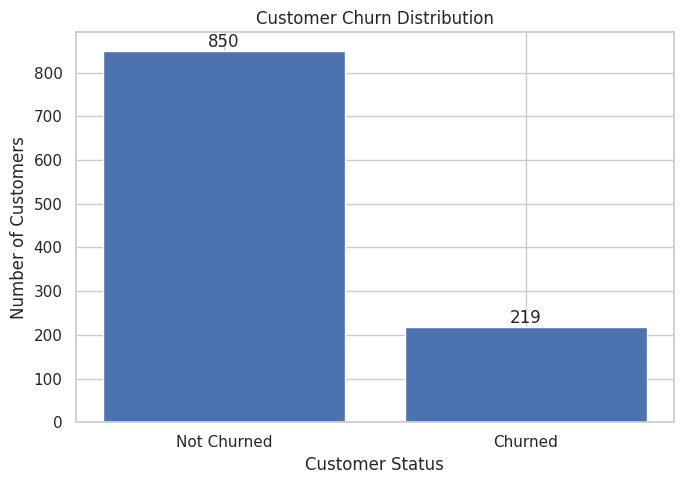

In [96]:
churn_counts = clean_df["Churn"].map({0: "Not Churned", 1: "Churned"}).value_counts()

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_counts.index, churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

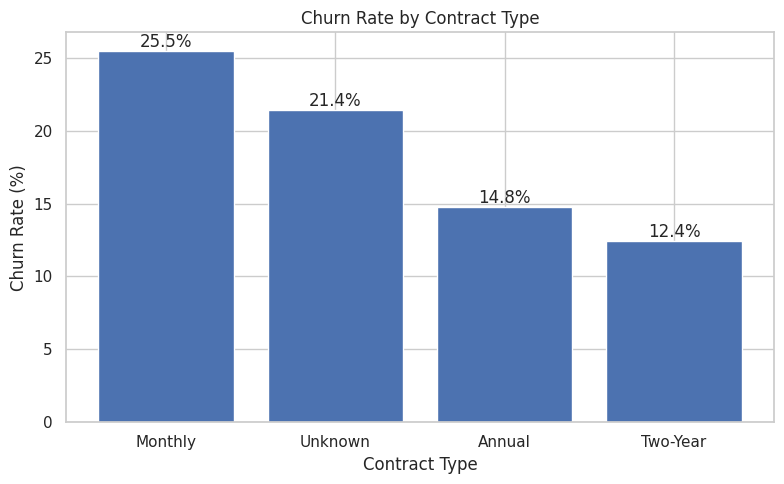

In [97]:
contract_churn = (
    clean_df.groupby("Contract_Type")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(contract_churn.index, contract_churn.values)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

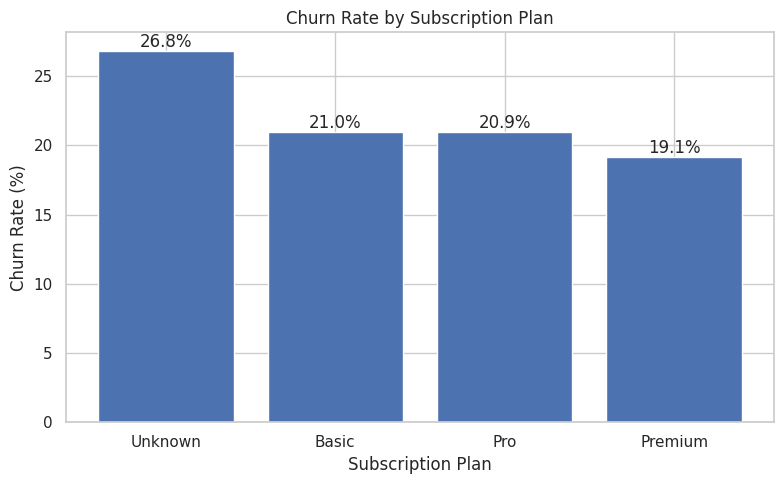

In [98]:
plan_churn = (
    clean_df.groupby("Subscription_Plan")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(plan_churn.index, plan_churn.values)
plt.title("Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

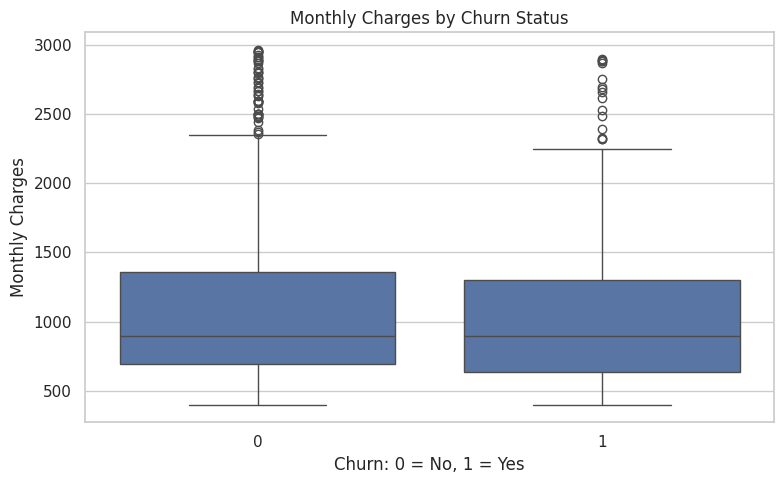

In [99]:
# 45. STEP 45

plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x="Churn", y="Monthly_Charges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn: 0 = No, 1 = Yes")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

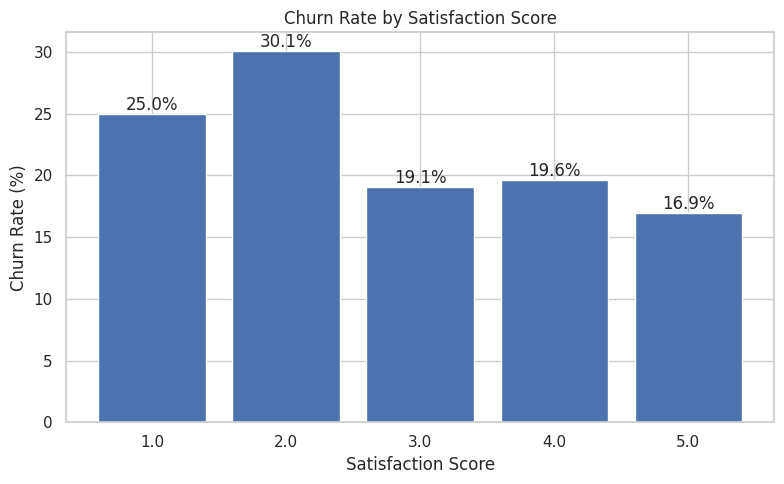

In [100]:
# 46. STEP 46

satisfaction_churn = (
    clean_df.groupby("Satisfaction_Score")["Churn"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(satisfaction_churn.index.astype(str), satisfaction_churn.values)
plt.title("Churn Rate by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

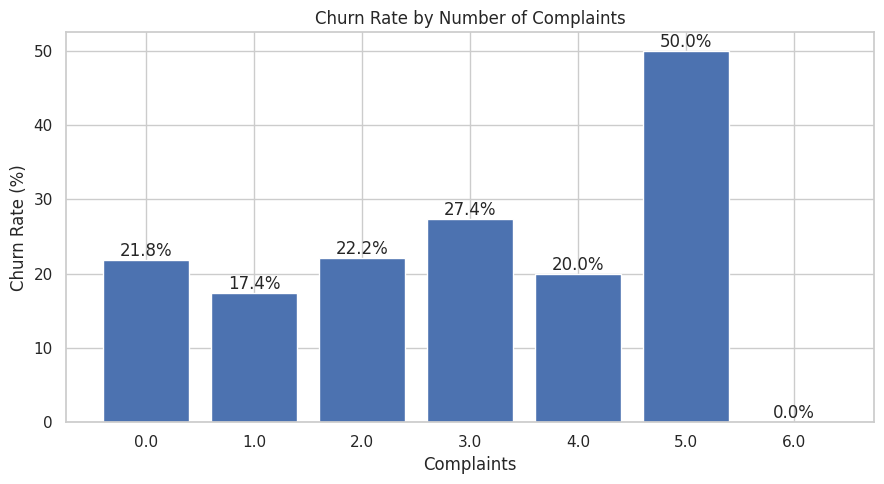

In [101]:
# 47. STEP 47

complaint_churn = (
    clean_df.groupby("Complaints")["Churn"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(9, 5))
bars = plt.bar(complaint_churn.index.astype(str), complaint_churn.values)
plt.title("Churn Rate by Number of Complaints")
plt.xlabel("Complaints")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

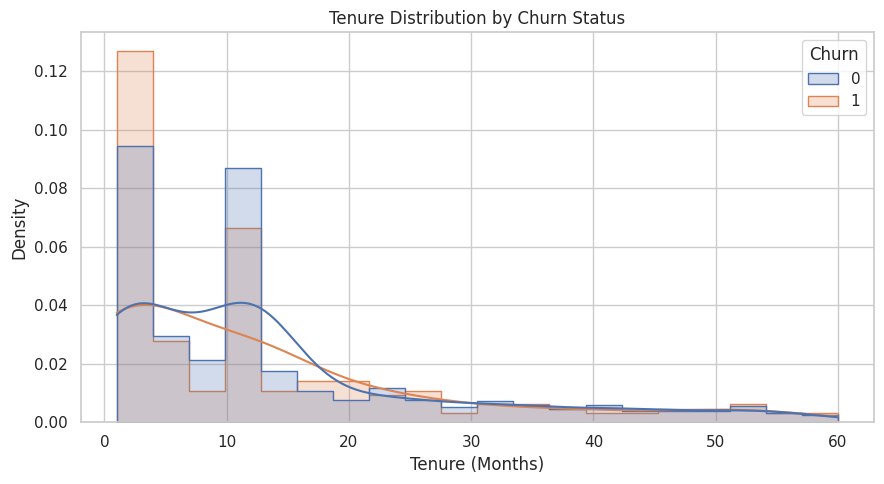

In [102]:
# 48. STEP 48

plt.figure(figsize=(9, 5))
sns.histplot(
    data=clean_df,
    x="Tenure_Months",
    hue="Churn",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

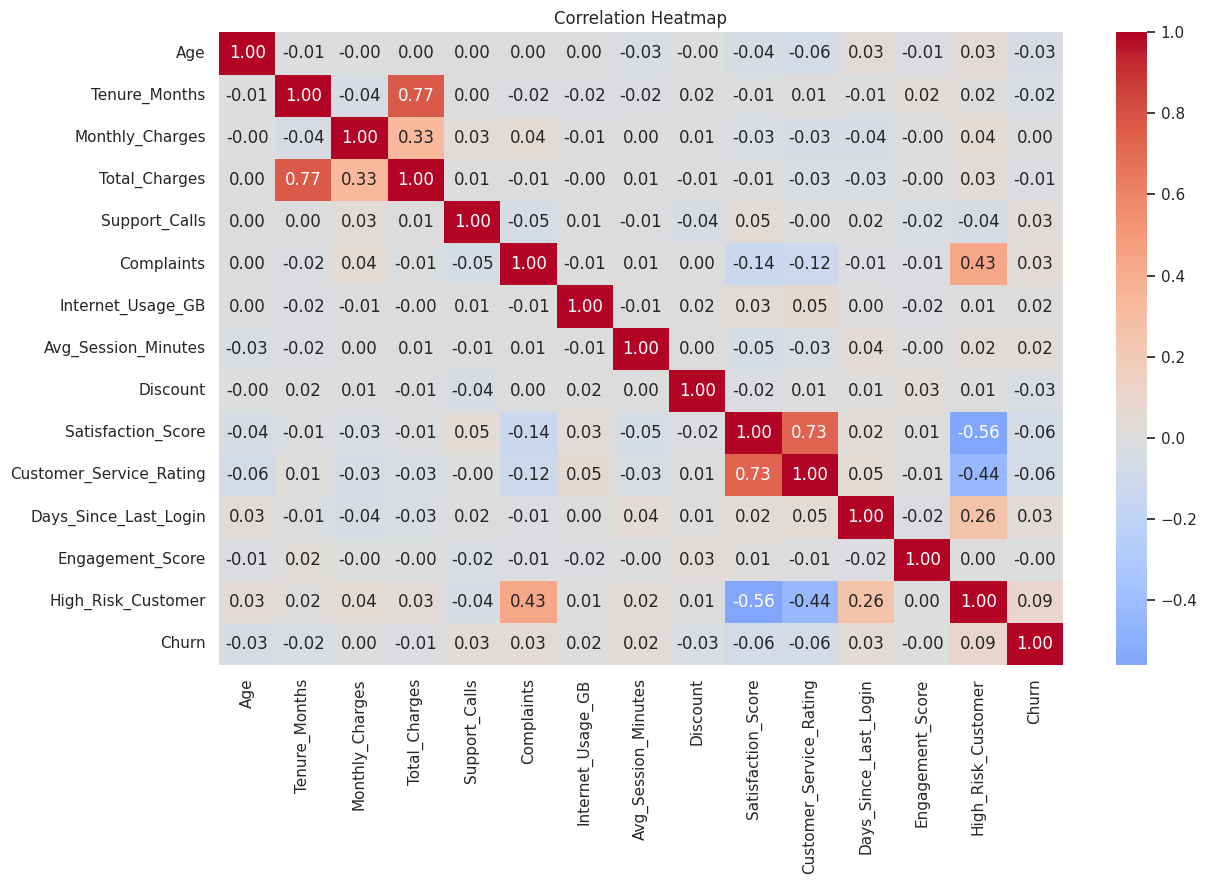

In [103]:
# 49. STEP 49

numeric_for_corr = [
    "Age", "Tenure_Months", "Monthly_Charges",
    "Total_Charges", "Support_Calls", "Complaints",
    "Internet_Usage_GB", "Avg_Session_Minutes",
    "Discount", "Satisfaction_Score",
    "Customer_Service_Rating", "Days_Since_Last_Login",
    "Engagement_Score", "High_Risk_Customer", "Churn"
]

corr = clean_df[numeric_for_corr].corr()

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [104]:
# 50. STEP 50

group_summary = clean_df.groupby("Churn")[[
    "Age", "Tenure_Months", "Monthly_Charges",
    "Support_Calls", "Complaints",
    "Satisfaction_Score", "Days_Since_Last_Login"
]].agg(["mean", "median", "std"]).round(2)

display(group_summary)

Age               Tenure_Months               Monthly_Charges         \
        mean median    std          mean median    std            mean median   
Churn                                                                           
0      35.81   35.0   9.98         13.90   12.0  13.95         1076.24  896.0   
1       35.0   35.0  10.17         13.03   10.0  14.43         1081.46  896.0   

              Support_Calls              Complaints               \
          std          mean median   std       mean median   std   
Churn                                                              
0      569.16          2.79    3.0  1.83       1.14    1.0  0.98   
1      607.29          2.92    3.0  1.83       1.23    1.0  1.09   

      Satisfaction_Score              Days_Since_Last_Login                
                    mean median   std                  mean median    std  
Churn                                                                      
0                   3.32    3.0  1.03                 11.46    7.0  30.57  
1                   3.15    3.0  1.08                 14.26    7.0  39.36

In [105]:
# 51. STEP 51

# H0: Mean satisfaction is the same for churned and non-churned customers.
# H1: Mean satisfaction differs between the two groups.

churned_satisfaction = clean_df.loc[clean_df["Churn"] == 1, "Satisfaction_Score"]
active_satisfaction = clean_df.loc[clean_df["Churn"] == 0, "Satisfaction_Score"]

t_stat, p_value = ttest_ind(
    churned_satisfaction,
    active_satisfaction,
    equal_var=False
)

print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 6))

if p_value < 0.05:
    print("Conclusion: Reject H0 at the 5% significance level.")
else:
    print("Conclusion: Fail to reject H0 at the 5% significance level.")

T-statistic: -2.039
P-value: 0.042247
Conclusion: Reject H0 at the 5% significance level.


In [106]:
# 52. STEP 52

# ANOVA is performed on a numerical variable across multiple groups.
# Here we compare Monthly_Charges across contract groups.

groups = [
    group["Monthly_Charges"].values
    for _, group in clean_df.groupby("Contract_Type")
    if len(group) > 1
]

anova_stat, anova_p = f_oneway(*groups)

print("ANOVA F-statistic:", round(anova_stat, 4))
print("ANOVA p-value:", round(anova_p, 6))

if anova_p < 0.05:
    print("Conclusion: Reject H0 — at least one contract group has a different mean monthly charge.")
else:
    print("Conclusion: Fail to reject H0 — no statistically significant difference detected.")

ANOVA F-statistic: 0.8753
ANOVA p-value: 0.453331
Conclusion: Fail to reject H0 — no statistically significant difference detected.


In [107]:
# 53. STEP 53

contingency_table = pd.crosstab(
    clean_df["Contract_Type"],
    clean_df["Churn"]
)

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", round(p, 6))

display(contingency_table)

if p < 0.05:
    print("Conclusion: Contract Type and Churn are statistically associated.")
else:
    print("Conclusion: No statistically significant association detected.")

Chi-square statistic: 20.7969
Degrees of freedom: 3
P-value: 0.000116


Churn,0,1
Contract_Type,,
Annual,260,45
Monthly,430,147
Two-Year,127,18
Unknown,33,9


Conclusion: Contract Type and Churn are statistically associated.


In [108]:
# 54. STEP 54

payment_table = pd.crosstab(
    clean_df["Payment_Method"],
    clean_df["Churn"]
)

chi2_payment, p_payment, dof_payment, expected_payment = chi2_contingency(payment_table)

print("Chi-square statistic:", round(chi2_payment, 4))
print("Degrees of freedom:", dof_payment)
print("P-value:", round(p_payment, 6))

display(payment_table)

if p_payment < 0.05:
    print("Conclusion: Payment Method and Churn are statistically associated.")
else:
    print("Conclusion: No statistically significant association detected.")

Chi-square statistic: 3.7494
Degrees of freedom: 5
P-value: 0.586029


Churn,0,1
Payment_Method,,
Bank Transfer,196,52
Credit Card,254,74
Debit Card,186,43
Other,13,4
UPI,184,39
Unknown,17,7


Conclusion: No statistically significant association detected.


In [109]:
# 55. STEP 55

model_df = clean_df.copy()

# Remove columns that should not directly be used as predictors.
drop_columns = [
    "Customer_ID", "Customer_Name",
    "Signup_Date", "Last_Login", "Churn_Date",
    "Churn_Reason", "Customer_Notes",
    "Churn"
]

X = model_df.drop(columns=drop_columns)
y = model_df["Churn"]

# Convert categorical variables using one-hot encoding.
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Replace any remaining infinite/missing values.
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

print("Model feature shape:", X.shape)
print("Target shape:", y.shape)

Model feature shape: (1069, 270)
Target shape: (1069,)


In [110]:
# 56. STEP 56

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 855
Testing rows: 214
Training churn rate: 20.47 %
Testing churn rate: 20.56 %


In [111]:
# 57. STEP 57

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [112]:
# 58. STEP 58

log_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, log_pred))

print("Accuracy :", round(accuracy_score(y_test, log_pred), 4))
print("Precision:", round(precision_score(y_test, log_pred), 4))
print("Recall   :", round(recall_score(y_test, log_pred), 4))
print("F1 Score :", round(f1_score(y_test, log_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, log_prob), 4))

              precision    recall  f1-score   support

           0       0.80      0.91      0.85       170
           1       0.27      0.14      0.18        44

    accuracy                           0.75       214
   macro avg       0.54      0.52      0.52       214
weighted avg       0.69      0.75      0.71       214

Accuracy : 0.7477
Precision: 0.2727
Recall   : 0.1364
F1 Score : 0.1818
ROC-AUC  : 0.4957


In [113]:
# 59. STEP 59

tree_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=10,
    random_state=RANDOM_STATE
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, tree_pred))

print("Accuracy :", round(accuracy_score(y_test, tree_pred), 4))
print("Precision:", round(precision_score(y_test, tree_pred), 4))
print("Recall   :", round(recall_score(y_test, tree_pred), 4))
print("F1 Score :", round(f1_score(y_test, tree_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, tree_prob), 4))

              precision    recall  f1-score   support

           0       0.80      0.95      0.87       170
           1       0.33      0.09      0.14        44

    accuracy                           0.78       214
   macro avg       0.57      0.52      0.51       214
weighted avg       0.71      0.78      0.72       214

Accuracy : 0.7757
Precision: 0.3333
Recall   : 0.0909
F1 Score : 0.1429
ROC-AUC  : 0.4713


In [114]:
# 60. STEP 60

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred))

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("F1 Score :", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

              precision    recall  f1-score   support

           0       0.80      0.98      0.88       170
           1       0.25      0.02      0.04        44

    accuracy                           0.79       214
   macro avg       0.52      0.50      0.46       214
weighted avg       0.68      0.79      0.71       214

Accuracy : 0.785
Precision: 0.25
Recall   : 0.0227
F1 Score : 0.0417
ROC-AUC  : 0.546


In [115]:
# 61. STEP 61

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, xgb_pred))

print("Accuracy :", round(accuracy_score(y_test, xgb_pred), 4))
print("Precision:", round(precision_score(y_test, xgb_pred), 4))
print("Recall   :", round(recall_score(y_test, xgb_pred), 4))
print("F1 Score :", round(f1_score(y_test, xgb_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, xgb_prob), 4))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       170
           1       0.00      0.00      0.00        44

    accuracy                           0.75       214
   macro avg       0.39      0.47      0.43       214
weighted avg       0.62      0.75      0.68       214

Accuracy : 0.7523
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.5011


In [116]:
# 62. STEP 62

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, xgb_pred)
    ],
    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, xgb_pred)
    ],
    "F1": [
        f1_score(y_test, log_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, xgb_pred)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, tree_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
}).sort_values("ROC_AUC", ascending=False)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,Random Forest,0.7850,0.2500,0.0227,0.0417,0.5460
3,XGBoost,0.7523,0.0000,0.0000,0.0000,0.5011
0,Logistic Regression,0.7477,0.2727,0.1364,0.1818,0.4957
1,Decision Tree,0.7757,0.3333,0.0909,0.1429,0.4713


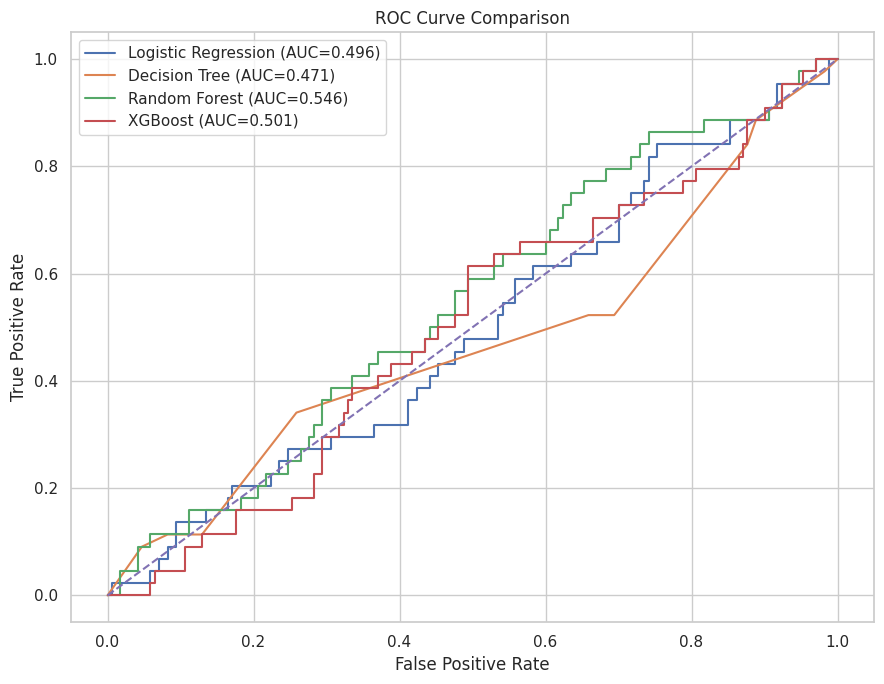

In [117]:
# 63. STEP 63

models_probabilities = {
    "Logistic Regression": log_prob,
    "Decision Tree": tree_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(9, 7))

for name, probabilities in models_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

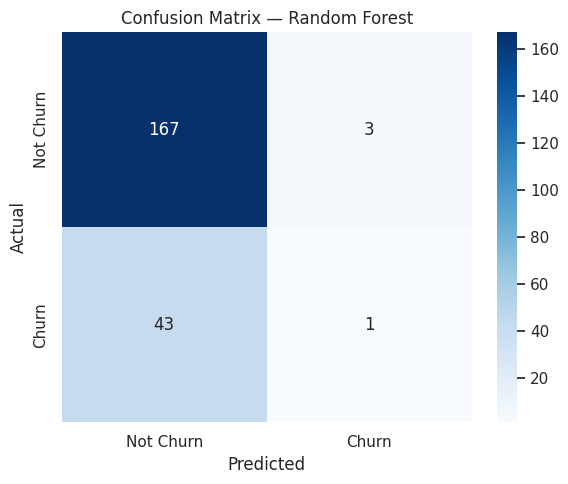

Best initial model: Random Forest


In [118]:
# 64. STEP 64

best_initial_name = results.iloc[0]["Model"]

pred_map = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

best_initial_pred = pred_map[best_initial_name]

cm = confusion_matrix(y_test, best_initial_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churn", "Churn"],
    yticklabels=["Not Churn", "Churn"]
)
plt.title(f"Confusion Matrix — {best_initial_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Best initial model:", best_initial_name)

In [119]:
# 65. STEP 65

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance.head(20))

,Feature,Importance
6,Internet_Usage_GB,0.055828
7,Avg_Session_Minutes,0.050531
0,Age,0.046897
2,Total_Charges,0.044072
1,Monthly_Charges,0.043876
15,Monthly_Revenue,0.041898
16,Estimated_Annual_Value,0.041329
14,Tenure_Months,0.037053
17,Support_Intensity,0.029263
9,Satisfaction_Score,0.025273


In [120]:
# 66. STEP 66

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(xgb_importance.head(20))

,Feature,Importance
33,City_Mangaluru,0.030665
21,Gender_Unknown,0.023055
44,City_Thiruvananthapuram,0.021925
19,High_Risk_Customer,0.018317
239,Contract_Type_Monthly,0.017986
45,City_Thrissur,0.017780
28,City_Hyderabad,0.017516
54,State_Kerala,0.017339
16,Estimated_Annual_Value,0.016395
43,City_Surat,0.015884


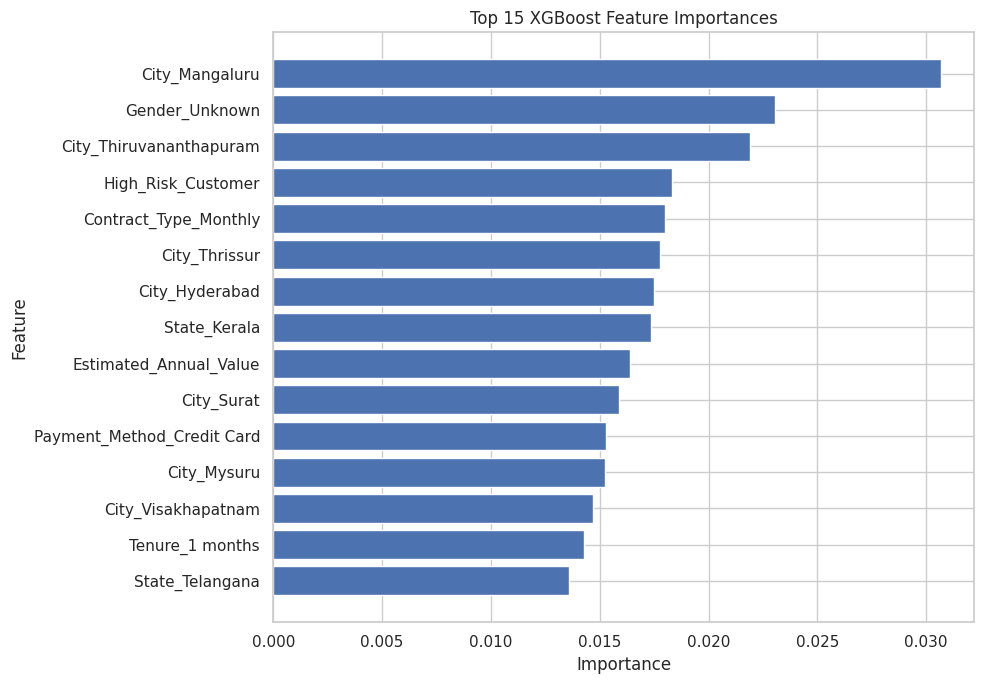

In [121]:
# 67. STEP 67

top15_xgb = xgb_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top15_xgb["Feature"], top15_xgb["Importance"])
plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [122]:
# 68. STEP 68

xgb_for_tuning = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [150, 250],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=xgb_for_tuning,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print("\nBest CV ROC-AUC:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 250, 'subsample': 0.8}

Best CV ROC-AUC: 0.5987


In [123]:
# 69. STEP 69

tuned_xgb = grid_search.best_estimator_

tuned_pred = tuned_xgb.predict(X_test)
tuned_prob = tuned_xgb.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision": precision_score(y_test, tuned_pred),
    "Recall": recall_score(y_test, tuned_pred),
    "F1": f1_score(y_test, tuned_pred),
    "ROC_AUC": roc_auc_score(y_test, tuned_prob)
}

print(classification_report(y_test, tuned_pred))

for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.4f}")

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       170
           1       0.11      0.02      0.04        44

    accuracy                           0.76       214
   macro avg       0.45      0.49      0.45       214
weighted avg       0.65      0.76      0.69       214

Accuracy: 0.7617
Precision: 0.1111
Recall: 0.0227
F1: 0.0377
ROC_AUC: 0.5039


In [124]:
# 70. STEP 70

tuned_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tuned_xgb.feature_importances_
}).sort_values("Importance", ascending=False)

TOP_N = 12
top_features = tuned_importance.head(TOP_N)["Feature"].tolist()

print(f"Selected top {TOP_N} features:")
for feature in top_features:
    print("-", feature)

X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

top_feature_model = XGBClassifier(
    **grid_search.best_params_,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

top_feature_model.fit(X_train_top, y_train)

top_pred = top_feature_model.predict(X_test_top)
top_prob = top_feature_model.predict_proba(X_test_top)[:, 1]

print("\nTop-feature model results:")
print("Accuracy :", round(accuracy_score(y_test, top_pred), 4))
print("Precision:", round(precision_score(y_test, top_pred), 4))
print("Recall   :", round(recall_score(y_test, top_pred), 4))
print("F1 Score :", round(f1_score(y_test, top_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, top_prob), 4))

Selected top 12 features:
- Gender_Unknown
- Login_Frequency_Rarely
- City_Hyderabad
- Contract_Type_Monthly
- City_Thrissur
- Referral_Source_Unknown
- State_Kerala
- Tenure_1 months
- City_Delhi
- City_New Delhi
- High_Risk_Customer
- Device_Type_Unknown

Top-feature model results:
Accuracy : 0.7617
Precision: 0.2308
Recall   : 0.0682
F1 Score : 0.1053
ROC-AUC  : 0.5701


In [125]:
# 71. STEP 71

final_model_comparison = pd.DataFrame({
    "Model": [
        "Tuned XGBoost - All Features",
        f"Tuned XGBoost - Top {TOP_N} Features"
    ],
    "Accuracy": [
        accuracy_score(y_test, tuned_pred),
        accuracy_score(y_test, top_pred)
    ],
    "Precision": [
        precision_score(y_test, tuned_pred),
        precision_score(y_test, top_pred)
    ],
    "Recall": [
        recall_score(y_test, tuned_pred),
        recall_score(y_test, top_pred)
    ],
    "F1": [
        f1_score(y_test, tuned_pred),
        f1_score(y_test, top_pred)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, tuned_prob),
        roc_auc_score(y_test, top_prob)
    ]
})

display(final_model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Tuned XGBoost - All Features,0.7617,0.1111,0.0227,0.0377,0.5039
1,Tuned XGBoost - Top 12 Features,0.7617,0.2308,0.0682,0.1053,0.5701


In [126]:
# 72. STEP 72

final_churn_rate = clean_df["Churn"].mean() * 100
total_customers = len(clean_df)
churned_customers = int(clean_df["Churn"].sum())
active_customers = total_customers - churned_customers

print("=" * 60)
print("FINAL CUSTOMER CHURN SUMMARY")
print("=" * 60)
print(f"Total Customers : {total_customers:,}")
print(f"Churned         : {churned_customers:,}")
print(f"Active          : {active_customers:,}")
print(f"Churn Rate      : {final_churn_rate:.2f}%")
print("=" * 60)

FINAL CUSTOMER CHURN SUMMARY
Total Customers : 1,069
Churned         : 219
Active          : 850
Churn Rate      : 20.49%


In [127]:
# 73. STEP 73

risk_summary = (
    clean_df.groupby("High_Risk_Customer")
    .agg(
        Customers=("Customer_ID", "count"),
        Churn_Rate=("Churn", "mean"),
        Avg_Satisfaction=("Satisfaction_Score", "mean"),
        Avg_Complaints=("Complaints", "mean"),
        Avg_Monthly_Charges=("Monthly_Charges", "mean")
    )
)

risk_summary["Churn_Rate"] *= 100

display(risk_summary.round(2))

,Customers,Churn_Rate,Avg_Satisfaction,Avg_Complaints,Avg_Monthly_Charges
High_Risk_Customer,,,,,
0,777,18.15,3.64,0.89,1062.21
1,292,26.71,2.33,1.87,1117.47


In [128]:
# 74. STEP 74

highest_contract = contract_churn.idxmax()
highest_contract_rate = contract_churn.max()

highest_plan = plan_churn.idxmax()
highest_plan_rate = plan_churn.max()

highest_complaint_group = complaint_churn.idxmax()
highest_complaint_rate = complaint_churn.max()

print("KEY BUSINESS INSIGHTS")
print("-" * 70)
print(f"1. Overall customer churn rate: {final_churn_rate:.2f}%")
print(f"2. Contract type with highest observed churn: {highest_contract} ({highest_contract_rate:.2f}%)")
print(f"3. Subscription plan with highest observed churn: {highest_plan} ({highest_plan_rate:.2f}%)")
print(f"4. Complaint group with highest observed churn: {highest_complaint_group} complaints ({highest_complaint_rate:.2f}%)")
print(f"5. Best initial classification model by ROC-AUC: {best_initial_name}")
print(f"6. Tuned XGBoost ROC-AUC: {roc_auc_score(y_test, tuned_prob):.4f}")
print(f"7. Top {TOP_N} features were used to test whether a smaller feature set could retain useful predictive performance.")

KEY BUSINESS INSIGHTS
----------------------------------------------------------------------
1. Overall customer churn rate: 20.49%
2. Contract type with highest observed churn: Monthly (25.48%)
3. Subscription plan with highest observed churn: Unknown (26.83%)
4. Complaint group with highest observed churn: 5.0 complaints (50.00%)
5. Best initial classification model by ROC-AUC: Random Forest
6. Tuned XGBoost ROC-AUC: 0.5039
7. Top 12 features were used to test whether a smaller feature set could retain useful predictive performance.
